In [2]:
# Carga las librerías, define las rutas y lee el dataset limpio (sin las 13 imágenes eliminadas) para analizarlo.

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Rutas del proyecto
PROYECTO = Path("..")
RESULTADOS = PROYECTO / "Resultados"
GRAFICOS = PROYECTO / "Graficos"

# Cargar el dataset limpio generado en el notebook 02
df = pd.read_csv(RESULTADOS / "dataset_limpio.csv")
print(f"Imágenes cargadas: {len(df)}")
df.head()

Imágenes cargadas: 15326


,split,carpeta,emocion,archivo,ruta,brillo,contraste,nitidez,diferencia_color,muy_oscura,sin_contraste,muy_borrosa,es_gris,eliminada
0,test,5,Tristeza,test_0001_aligned.jpg,..\base_expresiones_faciales\DATASET\test\5\te...,108.6984,61.297490,929.553697,23.34925,False,False,False,False,False
1,test,1,Sorpresa,test_0002_aligned.jpg,..\base_expresiones_faciales\DATASET\test\1\te...,142.7881,64.228417,1052.089335,17.33475,False,False,False,False,False
2,test,4,Felicidad,test_0003_aligned.jpg,..\base_expresiones_faciales\DATASET\test\4\te...,151.0388,56.980376,453.672083,22.81700,False,False,False,False,False
3,test,1,Sorpresa,test_0004_aligned.jpg,..\base_expresiones_faciales\DATASET\test\1\te...,159.8074,53.024705,755.612446,19.10150,False,False,False,False,False
4,test,5,Tristeza,test_0005_aligned.jpg,..\base_expresiones_faciales\DATASET\test\5\te...,133.2026,50.468734,643.298994,0.00000,False,False,False,True,False


In [3]:
# Calcula promedio, desvío, mínimo, mediana y máximo de cada medida, separado por emoción, para compararlas.
orden = ["Felicidad", "Neutral", "Tristeza", "Sorpresa", "Asco", "Enojo", "Miedo"]

for medida in ["brillo", "contraste", "nitidez"]:
    tabla = df.groupby("emocion")[medida].agg(["mean", "std", "min", "median", "max"]).loc[orden]
    print(f"--- {medida.upper()} por emoción ---")
    display(tabla.round(1))

--- BRILLO por emoción ---


,mean,std,min,median,max
emocion,,,,,
Felicidad,125.7,33.8,25.9,125.2,233.9
Neutral,119.4,34.7,25.0,119.4,238.6
Tristeza,120.1,33.7,27.0,121.4,220.2
Sorpresa,130.0,35.4,32.9,131.4,232.9
Asco,123.1,31.8,25.8,124.4,207.1
Enojo,118.0,33.5,25.6,117.5,214.1
Miedo,105.6,35.0,30.9,101.4,214.2


--- CONTRASTE por emoción ---


,mean,std,min,median,max
emocion,,,,,
Felicidad,45.6,13.6,9.6,44.3,98.1
Neutral,50.4,15.6,10.4,49.3,107.9
Tristeza,50.9,15.2,9.8,49.7,105.3
Sorpresa,50.8,15.0,13.2,49.7,113.5
Asco,50.1,14.0,10.6,49.0,92.6
Enojo,56.9,16.2,14.2,56.3,113.3
Miedo,57.4,16.3,17.4,56.7,102.7


--- NITIDEZ por emoción ---


,mean,std,min,median,max
emocion,,,,,
Felicidad,579.9,847.5,6.4,313.5,20522.3
Neutral,789.4,1357.1,5.2,379.9,36098.5
Tristeza,990.0,1318.3,16.0,582.3,17087.0
Sorpresa,1031.6,1307.5,8.2,640.6,24494.8
Asco,698.4,891.7,8.6,386.9,7487.1
Enojo,1344.4,1639.4,9.0,832.5,15290.5
Miedo,1426.9,1549.1,7.3,921.2,9785.8


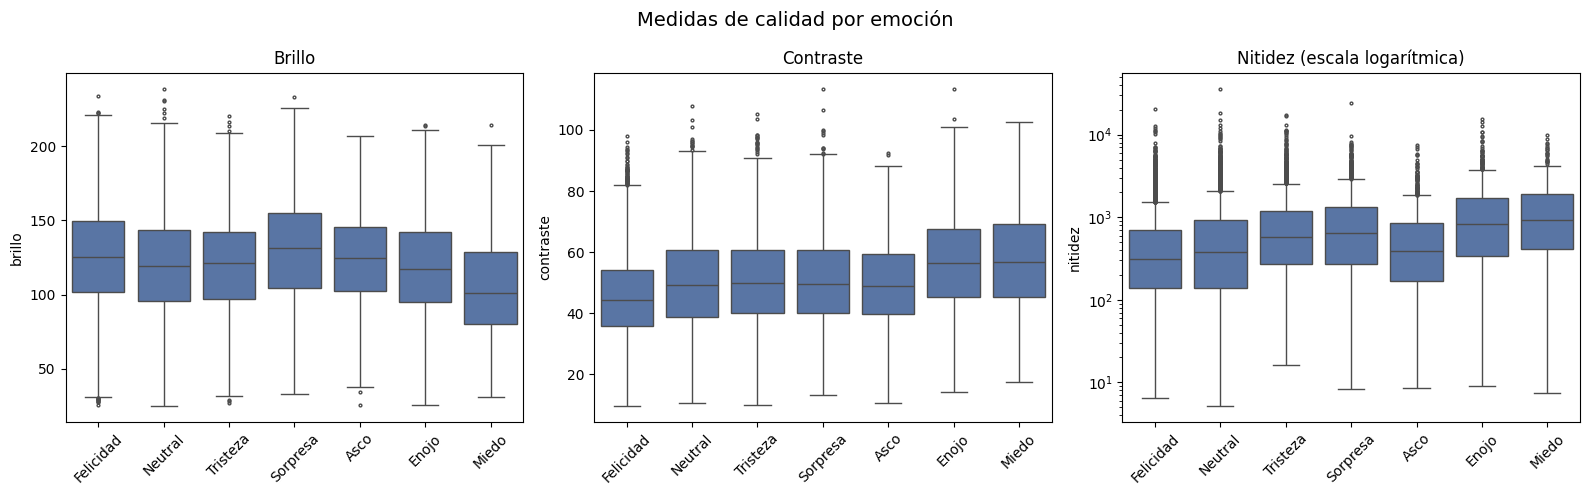

In [4]:
# Dibuja un diagrama de caja de cada medida por emoción para comparar de un vistazo cómo se reparten los valores.
orden = ["Felicidad", "Neutral", "Tristeza", "Sorpresa", "Asco", "Enojo", "Miedo"]

fig, ejes = plt.subplots(1, 3, figsize=(16, 5))
for eje, medida in zip(ejes, ["brillo", "contraste", "nitidez"]):
    sns.boxplot(data=df, x="emocion", y=medida, order=orden, ax=eje, color="#4C72B0", fliersize=2)
    eje.set_title(medida.capitalize())
    eje.set_xlabel("")
    eje.tick_params(axis="x", rotation=45)

ejes[2].set_yscale("log")
ejes[2].set_title("Nitidez (escala logarítmica)")
plt.suptitle("Medidas de calidad por emoción", fontsize=14)
plt.tight_layout()
plt.savefig(GRAFICOS / "03_cajas_por_emocion.png", dpi=150)
plt.show()

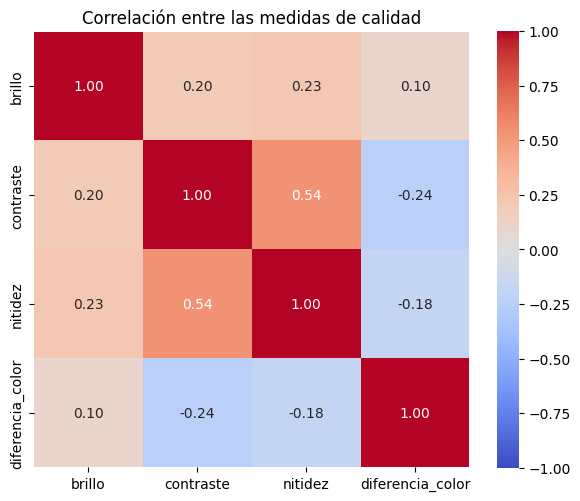

In [5]:
# Calcula la correlación entre las medidas y la dibuja como mapa de calor para ver cuáles se relacionan.
medidas = ["brillo", "contraste", "nitidez", "diferencia_color"]
correlacion = df[medidas].corr(method="spearman")

plt.figure(figsize=(6, 5))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlación entre las medidas de calidad")
plt.tight_layout()
plt.savefig(GRAFICOS / "03_correlacion_medidas.png", dpi=150)
plt.show()

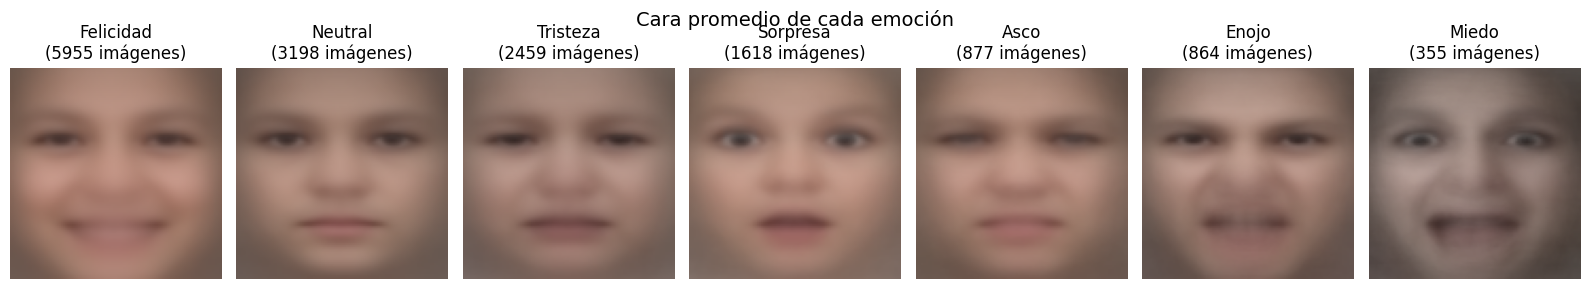

In [6]:
# Promedia los píxeles de todas las imágenes de cada emoción para ver el rasgo típico de cada una.
import cv2

orden = ["Felicidad", "Neutral", "Tristeza", "Sorpresa", "Asco", "Enojo", "Miedo"]

fig, ejes = plt.subplots(1, 7, figsize=(16, 3))
for eje, emocion in zip(ejes, orden):
    rutas = df.loc[df["emocion"] == emocion, "ruta"]
    suma = np.zeros((100, 100, 3))
    for ruta in rutas:
        suma += cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2RGB)
    promedio = (suma / len(rutas)).astype("uint8")
    eje.imshow(promedio)
    eje.set_title(f"{emocion}\n({len(rutas)} imágenes)")
    eje.axis("off")

plt.suptitle("Cara promedio de cada emoción", fontsize=14)
plt.tight_layout()
plt.savefig(GRAFICOS / "03_cara_promedio.png", dpi=150)
plt.show()

In [7]:
# Guarda un resumen por emoción (cantidad y medidas de calidad) en un CSV para cargarlo en Power BI.
resumen = df.groupby("emocion").agg(
    imagenes=("archivo", "count"),
    brillo_mediana=("brillo", "median"),
    contraste_mediana=("contraste", "median"),
    nitidez_mediana=("nitidez", "median"),
).reset_index()
resumen["porcentaje"] = (resumen["imagenes"] / len(df) * 100).round(1)

resumen.to_csv(RESULTADOS / "resumen_emociones.csv", index=False, encoding="utf-8-sig")
resumen.round(1)

,emocion,imagenes,brillo_mediana,contraste_mediana,nitidez_mediana,porcentaje
0,Asco,877,124.4,49.0,386.9,5.7
1,Enojo,864,117.5,56.3,832.5,5.6
2,Felicidad,5955,125.2,44.3,313.5,38.9
3,Miedo,355,101.4,56.7,921.2,2.3
4,Neutral,3198,119.4,49.3,379.9,20.9
5,Sorpresa,1618,131.4,49.7,640.6,10.6
6,Tristeza,2459,121.4,49.7,582.3,16.0
